## ML training on sklearn dataset

In [2]:
import random
import torch
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline


In [3]:
np.random.seed(1337)
random.seed(1337)

In [ ]:
# Let's make up a dataset
from sklearn.datasets import make_moons, make_blobs
X, y = make_moons(n_samples=100, noise=0.1)

# make y be -1 or 1
y = y*2 - 1

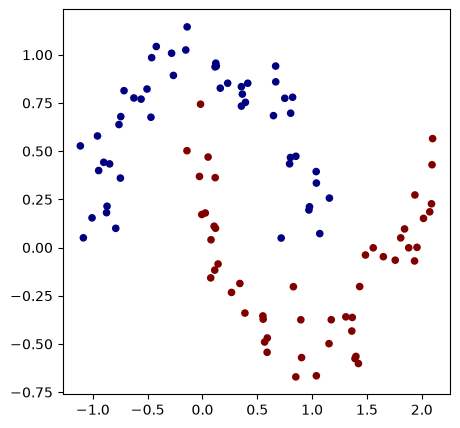

In [24]:
# Visualize in 2D
plt.figure(figsize=(5,5))
plt.scatter(X[:,0], X[:,1], c=y, s=20, cmap='jet')

In [ ]:
# Let's train an MLP to output whether it is a one or zero

array([ 1.88101391, -0.13978292, -0.87027504,  0.07525312,  1.758169  ,
        0.58961949,  1.1745536 ,  1.55717533,  0.55101677,  1.30772759,
        1.84297393, -0.84666874,  1.03844059,  2.07264872,  0.41300349,
        0.39176231,  2.09362901, -0.76122137,  0.11491   ,  0.80428525,
        0.85132372,  0.5538434 ,  0.11606056,  0.66727537,  0.35501576,
        1.154022  ,  2.09881996,  0.64763829,  0.22990014,  1.42221204,
        1.80806708,  0.10619674,  0.11189076, -0.01768776,  1.9563485 ,
        1.36173586, -0.50568735,  0.12601376, -0.26500879,  0.34110814,
        1.64964762,  0.0512925 ,  1.39098104,  2.08851394,  1.937237  ,
        0.26478663, -0.02725912,  0.82197391,  0.35510601,  0.12182599,
       -1.0071297 ,  0.66820133,  0.8025394 , -0.74485402, -0.87461128,
       -0.74856464, -0.71532277,  0.07804247,  0.75069279,  0.59115987,
        0.38725643,  0.02593991, -0.46974417, -0.28158602,  1.48636834,
       -0.95746548, -1.08618674, -0.62539273, -0.46319959,  1.15

In [23]:
y

array([ 1, -1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1,  1,  1, -1, -1,  1,
       -1, -1, -1,  1,  1,  1, -1, -1,  1,  1, -1, -1,  1,  1,  1,  1,  1,
        1,  1, -1, -1, -1,  1,  1,  1,  1,  1,  1,  1,  1, -1, -1, -1, -1,
       -1, -1, -1, -1, -1, -1,  1, -1,  1,  1,  1, -1, -1,  1, -1, -1, -1,
       -1, -1, -1, -1,  1,  1,  1, -1, -1,  1, -1,  1,  1, -1,  1,  1, -1,
        1,  1, -1, -1, -1,  1, -1, -1,  1, -1, -1,  1, -1, -1, -1])

## 2.1 Lean Pytorch Implementation

In [37]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import make_moons

# 1. Data
X, y = make_moons(n_samples=100, noise=0.1, random_state=42)
X = torch.tensor(X, dtype=torch.float32)
y = torch.tensor(y*2 - 1, dtype=torch.float32)

# 2. Model, Optimizer (with built-in L2 weight decay), and Scheduler
model = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 16), nn.ReLU(),
    nn.Linear(16, 1), nn.Flatten(0) # Flattens (B, 1) -> (B,)
)
optimizer = torch.optim.SGD(model.parameters(), lr=1.0, weight_decay=2e-4)
scheduler = torch.optim.lr_scheduler.LinearLR(optimizer, start_factor=1.0, end_factor=0.1, total_iters=100)

# 3. Training Loop
model.train()
for step in range(1000):
    optimizer.zero_grad(set_to_none=True)
    loss = F.relu( 1.0 - y * model(X)).mean() # SVM Hinge Loss
    loss.backward()
    optimizer.step()
    scheduler.step()

# 4. Evaluation
model.eval()
with torch.inference_mode():
    acc = ((model(X) >= 0) == (y > 0)).float().mean().item()
    print(f"Final loss: {loss.item():.4f} | Accuracy: {acc * 100:.1f}%")

Final loss: 0.0013 | Accuracy: 100.0%


## 2.2 Pytorch Implementation with validation

In [40]:
import random
import matplotlib.pyplot as plt
import numpy as np

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler


In [41]:
# 0. Reproducibility and Device
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

In [ ]:
# 1. Data, Stratified Split & Leak-Free Standardization
X_np, y_np = make_moons(n_samples=200, noise=0.15, random_state=SEED)
y_np = y_np * 2 - 1 # Map {0, 1} -> {-1, +1}

X_tr_np, X_va_np, y_tr_np, y_va_np = train_test_split(
    X_np, y_np, test_size=0.25, stratify=y_np, random_state=SEED
)

# Fit scaler ONLY on training data to prevent validation data leakage
scaler = StandardScaler()
X_tr_np = scaler.fit_transform(X_tr_np)
X_va_np = scaler.transform(X_va_np)

X_tr = torch.tensor(X_tr_np, dtype=torch.float32, device=device)
y_tr = torch.tensor(y_tr_np, dtype=torch.float32, device=device)
X_va = torch.tensor(X_va_np, dtype=torch.float32, device=device)
y_va = torch.tensor(y_va_np, dtype=torch.float32, device=device)

# 2. Model, Explicit Weight Initialization, Parameter Groups & Scheduler
steps = 1000
model = nn.Sequential(
    nn.Linear(2, 16), nn.ReLU(),
    nn.Linear(16, 16), nn.ReLU(),
    nn.Linear(16, 1), nn.Flatten(0)
).to(device)

def init_weights(m: nn.Module) -> None:
    if isinstance(m, nn.Linear):
        # Xavier for linear outputn layer; Kaiming (He) for ReLU hidden Layers
        if m is model[-2]:
            nn.init.xavier_normal_(m.weight)
        else:
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")
        nn.init.zeros_(m.bias)

model.apply(init_weights) # initializing weights

# Verify trainable parameter count: (2*16+16) + (16*16+16) + (16*1+1) = 337
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Device {device} | Trainable parameters: {trainable_params}")


# Exclude 1D biases from L2 weight decay (standard ML regularization practice)
decay_params = [p for p in model.parameters() if p.requires_grad and p.ndim >=2]
no_decay_params = [p for p in model.parameters() if p.requires_grad and p.ndim < 2]

optimizer = torch.optim.SGD(
    [
        {"params": decay_params, "weight_decay": 2e-4},
        {"params": no_decay_params, "weight_decay": 0.0}
    ],
    lr=1.0,
)
scheduler = torch.optim.lr_scheduler.LinearLR(
    optimizer, start_factor=1.0, end_factor=0.1, total_iters=steps
)

# 3. Training & Evaluation Loop
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "grad_norm": []}

for step in range(steps):
    # Train step
    model.train()
    optimizer.zero_grad(set_to_none=True)
    tr_logits = model(X_tr)
    tr_loss = F.relu(1.0 - y_tr * tr_logits).mean() # SVM Hinge Loss
    tr_loss.backward()

    # Clip gradients to prevent exploding updates and log total L2 norm
    grad_norm = nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
    optimizer.step()
    scheduler.step()

    # Evaluation step
    model.eval()
    with torch.inference_mode():
        va_logits = model(X_va)
        va_loss = F.relu(1.0 - y_va * va_logits).mean()
        tr_acc = ((tr_logits.detach() >= 0) == (y_tr > 0)).float().mean().item()
        va_acc = ((va_logits >= 0) == (y_va > 0)).float().mean().item()

    history["train_loss"].append(tr_loss.item())
    history["val_loss"].append(va_loss.item())
    history["train_acc"].append(tr_acc * 100)
    history["val_acc"].append(va_acc * 100)
    history["grad_norm"].append(grad_norm.item())

print(
    f"Final Train | Loss: {history["train_loss"][-1]:.4f} | Acc: {history["train_acc"][-1]:.1f}%\n"
    f"Final Val   | Loss: {history['val_loss'][-1]:.4f} | Acc: {history['val_acc'][-1]:.1f}%"
)


Device mps | Trainable parameters: 337
Final Train | Loss: 0.0000 | Acc: 100.0%
Final Val   | Loss: 0.0588 | Acc: 96.0%


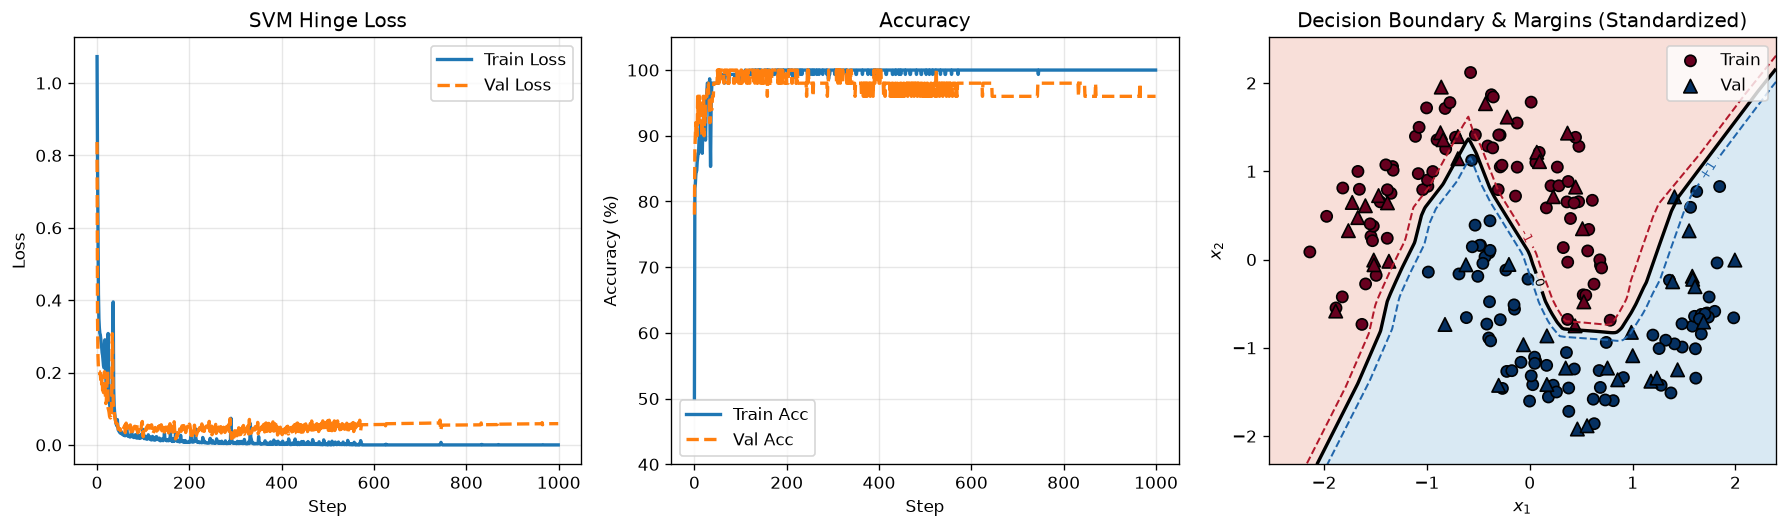

In [54]:
# 4. Diagnostic Figures (Loss, Accuracy, Decision Boundary & Margins)
model.eval()
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), dpi=120)

# Panel 1: Loss Curves
axes[0].plot(history["train_loss"], label="Train Loss", lw=2)
axes[0].plot(history["val_loss"], label="Val Loss", lw=2, ls="--")
axes[0].set(title="SVM Hinge Loss", xlabel="Step", ylabel="Loss")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

# Panel 2: Accuracy Curves
axes[1].plot(history["train_acc"], label="Train Acc", lw=2)
axes[1].plot(history["val_acc"], label="Val Acc", lw=2, ls="--")
axes[1].set(title="Accuracy", xlabel="Step", ylabel="Accuracy (%)", ylim=(40, 105))
axes[1].grid(True, alpha=0.3)
axes[1].legend()

# Panel 3: Decision Boundary & SVM Margins (-1, 0, +1)
X_scaled = np.vstack([X_tr_np, X_va_np])
x_min, x_max = X_scaled[:, 0].min() - 0.4, X_scaled[:, 0].max() + 0.4
y_min, y_max = X_scaled[:, 1].min() - 0.4, X_scaled[:, 1].max() + 0.4
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))

grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32, device=device)
with torch.inference_mode():
    Z = model(grid).cpu().numpy().reshape(xx.shape)

axes[2].contourf(xx, yy, Z >= 0, alpha=0.25, cmap=plt.cm.RdBu)
cs = axes[2].contour(
    xx, yy, Z, levels=[-1.0, 0.0, 1.0],
    colors=["#b2182b", "black", "#2166ac"], linestyles=["--", "-", "--"], linewidths=[1.2, 2.0, 1.2],
)
axes[2].clabel(cs, inline=True, fontsize=8, fmt={-1.0: "-1", 0.0: "0", 1.0: "+1"})
axes[2].scatter(X_tr_np[:, 0], X_tr_np[:, 1], c=y_tr_np, cmap=plt.cm.RdBu, edgecolors="k", s=45, label="Train")
axes[2].scatter(X_va_np[:, 0], X_va_np[:, 1], c=y_va_np, cmap=plt.cm.RdBu, edgecolors="k", marker="^", s=65, label="Val")
axes[2].set(title="Decision Boundary & Margins (Standardized)", xlabel="$x_1$", ylabel="$x_2$")
axes[2].legend(loc="upper right")

plt.tight_layout()
plt.show()


In [47]:
model

Sequential(
  (0): Linear(in_features=2, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=16, bias=True)
  (3): ReLU()
  (4): Linear(in_features=16, out_features=1, bias=True)
  (5): Flatten(start_dim=0, end_dim=-1)
)